# Projeto Praso — Previsão de Inadimplência
## EDA: Dados de Aplicação de Clientes (`credito_aplicacao_clientes_final.csv`)

### 📌 Propósito deste Notebook
> **Nota de Contexto**: Este bloco introdutório apresenta a contextualização e o objetivo das análises preliminares da base de clientes. Futuramente, ao término de todas as análises e decisões metodológicas, esta seção será atualizada para consolidar um **Sumário Executivo** completo com os principais achados, padrões de risco e direcionamentos para a modelagem.

O objetivo fundamental deste notebook é conduzir uma **Análise Exploratória de Dados (EDA) rigorosa** sobre as variáveis cadastrais, financeiras e digitais dos clientes da Praso. Esse conjunto forma a base do **Modelo de Aplicação (Cold Start)**, cujo papel estratégico na startup é responder no ato do cadastro: *qual a probabilidade de um novo varejista, sem histórico transacional prévio na Praso, não honrar suas compras a prazo?*

---

### 🧱 Separação e Dicionário das Features Brutas
O dataset contém **19 variáveis brutas**, categorizadas logicamente nas seguintes frentes de informação:

1. **Identificação e Geografia**:
   - `id_cliente`: Identificador numérico único do cliente (chave primária / foreign key com pedidos).
   - `uf`: Unidade Federativa do estabelecimento comercial (ex.: CE, PE).
   - `municipio`: Município sede do varejista (ex.: RECIFE, CAUCAIA, FORTALEZA).

2. **Perfil Cadastral, Jurídico e Econômico (Receita Federal)**:
   - `segmento_cliente`: Ramo de atuação do estabelecimento (anonimizado entre Segmento 1 a 21).
   - `natureza_juridica`: Regime jurídico do negócio (ex.: `213-5 - Empresário (Individual)`, `206-2 - Sociedade Empresária Limitada`).
   - `fonte_cliente`: Canal de aquisição do cliente (anonimizado entre Fonte 1 a 5).
   - `cnae_codigo`: Código da Classificação Nacional de Atividades Econômicas (ex.: `77.49-8-16`), preservando divisão, grupo e classe.
   - `capital_social`: Faixa de capital investido informado no registro formal da empresa (intervalar, ex.: `(1500, 2000]`).
   - `idade_cnpj`: Tempo de existência formal da empresa em dias desde a abertura na SEFAZ até o cadastro na Praso (intervalar, ex.: `(3000, 4000]`).

3. **Histórico de Crédito e Restrições Formais (Serasa / Birô)**:
   - `serasa_contagem_negativacoes`: Contagem total de registros de dívidas vencidas e não pagas em sistemas de proteção ao crédito.
   - `serasa_contagem_protestos`: Contagem de títulos levados a protesto formal em cartórios.
   - `serasa_credores`: Empresas/setores para os quais o cliente possui dívidas ativas (lista textual de até 5 credores, ex.: `"Financeiro, Comércio, Tecnologia"`).
   - `serasa_socio_tem_negativacao`: Indicador booleano (0 ou 1) se algum sócio/pessoa física vinculada possui restrição cadastral.

4. **Presença e Reputação Digital (iFood & Google Maps)**:
   - `ifood_contagem_avaliacoes`: Quantidade de avaliações recebidas na plataforma iFood (nulo caso não atue no app).
   - `ifood_faixa_preco`: Faixa de preço de cardápio praticada no iFood (`$`, `$$`, `$$$`).
   - `google_maps_avaliacao`: Nota média de reputação dos consumidores no Google Maps (escala de 0 a 5).
   - `google_maps_contagem_avaliacoes`: Volume total de avaliações no Google Maps.
   - `google_maps_tem_website`: Indicador booleano (0 ou 1) se o estabelecimento possui website oficial linkado no Maps.

5. **Variável Alvo (Target Supervisionado)**:
   - `inadimplente`: Indicador de inadimplência do cliente (0.0 = Adimplente, 1.0 = Inadimplente).


In [3]:
# 1. Configuração do Ambiente e Importação de Bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configurações visuais e de precisão
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

print("Ambiente configurado com sucesso!")


Ambiente configurado com sucesso!


### 1. Compreensão Estrutural e Carga dos Dados
Carregamento do arquivo `credito_aplicacao_clientes_final.csv` e validação de dimensionalidade, duplicatas e amostra inicial.


In [4]:
# Leitura do dataset de clientes
df_clientes = pd.read_csv('data/datasets/credito_aplicacao_clientes_final.csv')

n_linhas, n_colunas = df_clientes.shape
n_clientes_unicos = df_clientes['id_cliente'].nunique()
n_duplicatas = df_clientes.duplicated().sum()

print(f"Dimensões do Dataset: {n_linhas} linhas x {n_colunas} colunas")
print(f"Total de Clientes Únicos (id_cliente): {n_clientes_unicos}")
print(f"Registros Duplicados Exatos: {n_duplicatas}")

# Visualização das 5 primeiras observações
df_clientes.head()


Dimensões do Dataset: 3000 linhas x 19 colunas
Total de Clientes Únicos (id_cliente): 3000
Registros Duplicados Exatos: 0


,id_cliente,uf,municipio,segmento_cliente,natureza_juridica,fonte_cliente,cnae_codigo,capital_social,idade_cnpj,serasa_contagem_negativacoes,serasa_contagem_protestos,serasa_credores,serasa_socio_tem_negativacao,ifood_contagem_avaliacoes,ifood_faixa_preco,google_maps_avaliacao,google_maps_contagem_avaliacoes,google_maps_tem_website,inadimplente
0,1000732585882,CE,CAUCAIA,Segmento 2,213-5 - Empresário (Individual),Fonte 1,77.49-8-16,"(1500, 2000]","(3000, 4000]",0.000,0.000,NaN,0.000,"(50, 100]",$$,NaN,NaN,NaN,0.000
1,1001250740869,CE,FORTALEZA,Segmento 10,206-2 - Sociedade Empresária Limitada,Fonte 5,39.87-6-92,"(8000, 10000]","(25, 50]",3.000,0.000,NaN,0.000,NaN,NaN,NaN,NaN,NaN,0.000
2,1002669165825,CE,CAUCAIA,Segmento 20,213-5 - Empresário (Individual),Fonte 1,53.35-1-24,"(1500, 2000]","(3000, 4000]",5.000,0.000,"Financeiro, Comércio, Tecnologia",1.000,NaN,NaN,NaN,NaN,NaN,0.000
3,1003899664289,CE,FORTALEZA,Segmento 16,213-5 - Empresário (Individual),Fonte 1,77.74-5-45,"(2000, 3000]","(900, 1150]",0.000,0.000,NaN,0.000,NaN,NaN,NaN,NaN,NaN,0.000
4,1005577842775,CE,FORTALEZA,Segmento 18,213-5 - Empresário (Individual),Fonte 1,53.35-1-24,"(8000, 10000]","(600, 750]",1.000,1.000,Saúde,0.000,NaN,NaN,NaN,NaN,NaN,0.000


### 2. Mapeamento de Tipos e Análise de Valores Faltantes (Missing Values)
Avaliamos a presença de nulos em cada atributo. No contexto deste projeto, a ausência em variáveis digitais (Google Maps e iFood) ou de credores do Serasa é **informativa por domínio (MNAR - Missing Not at Random)**, indicando empresas que não operam via delivery ou que não possuem dívidas registradas no birô.


In [5]:
# Relatório estrutural de tipos e ausências
info_missing = pd.DataFrame({
    'Tipo Dtype': df_clientes.dtypes,
    'Valores Preenchidos': df_clientes.notnull().sum(),
    'Qtd Faltantes': df_clientes.isnull().sum(),
    '% Faltantes': (df_clientes.isnull().sum() / len(df_clientes) * 100).round(2),
    'Valores Únicos': df_clientes.nunique()
})

display(info_missing)


,Tipo Dtype,Valores Preenchidos,Qtd Faltantes,% Faltantes,Valores Únicos
id_cliente,int64,3000,0,0.000,3000
uf,str,3000,0,0.000,1
municipio,str,3000,0,0.000,36
segmento_cliente,str,3000,0,0.000,21
natureza_juridica,str,3000,0,0.000,5
fonte_cliente,str,3000,0,0.000,5
cnae_codigo,str,3000,0,0.000,153
capital_social,str,3000,0,0.000,19
idade_cnpj,str,3000,0,0.000,20
serasa_contagem_negativacoes,float64,3000,0,0.000,36


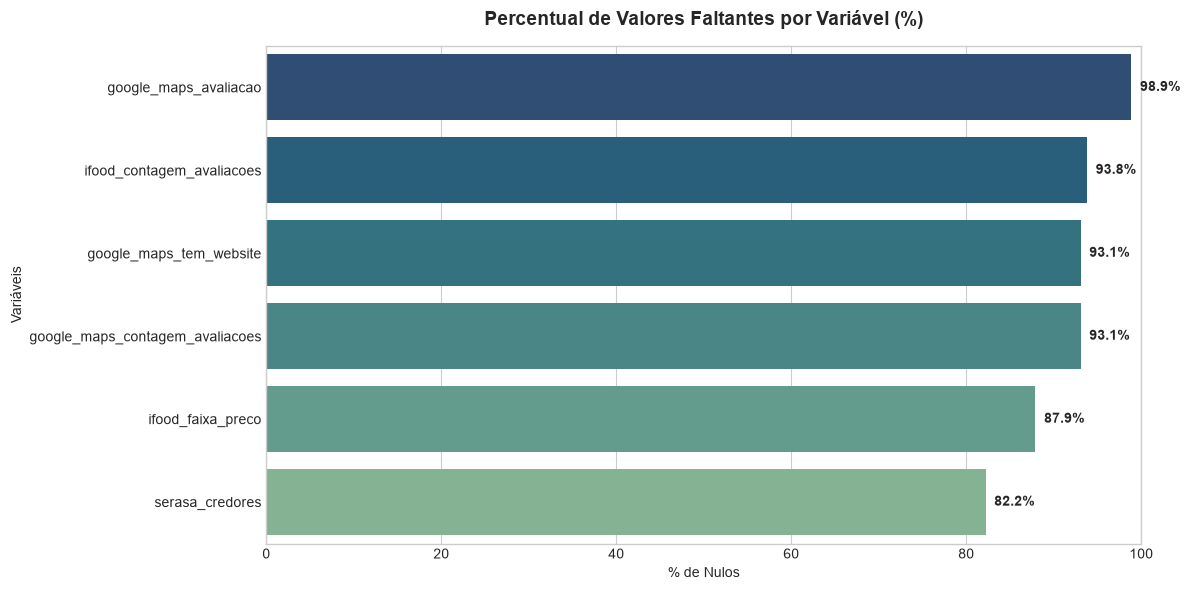

In [10]:
# Visualização gráfica do percentual de dados faltantes
missing_series = df_clientes.isnull().mean() * 100
missing_series = missing_series[missing_series > 0].sort_values(ascending=False)

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=missing_series.values, y=missing_series.index, palette='crest_r')
plt.title('Percentual de Valores Faltantes por Variável (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('% de Nulos')
plt.ylabel('Variáveis')
plt.xlim(0, 100)

for i, v in enumerate(missing_series.values):
    ax.text(v + 1, i, f"{v:.1f}%", va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


### 3. Análise da Variável Alvo (`inadimplente`)
Exame do balanceamento entre clientes adimplentes (0) e inadimplentes (1), métrica central para fundamentar a escolha de métricas como **ROC-AUC** e orientar estratégias de estratificação.


In [11]:
# Contagem absoluta e percentual do Target
contagem_target = df_clientes['inadimplente'].value_counts()
pct_target = df_clientes['inadimplente'].value_counts(normalize=True) * 100

tabela_target = pd.DataFrame({
    'Quantidade': contagem_target,
    'Proporção (%)': pct_target.round(2)
})
tabela_target.index = ['Adimplente (0.0)', 'Inadimplente (1.0)']
display(tabela_target)


,Quantidade,Proporção (%)
Adimplente (0.0),2060,68.670
Inadimplente (1.0),940,31.330


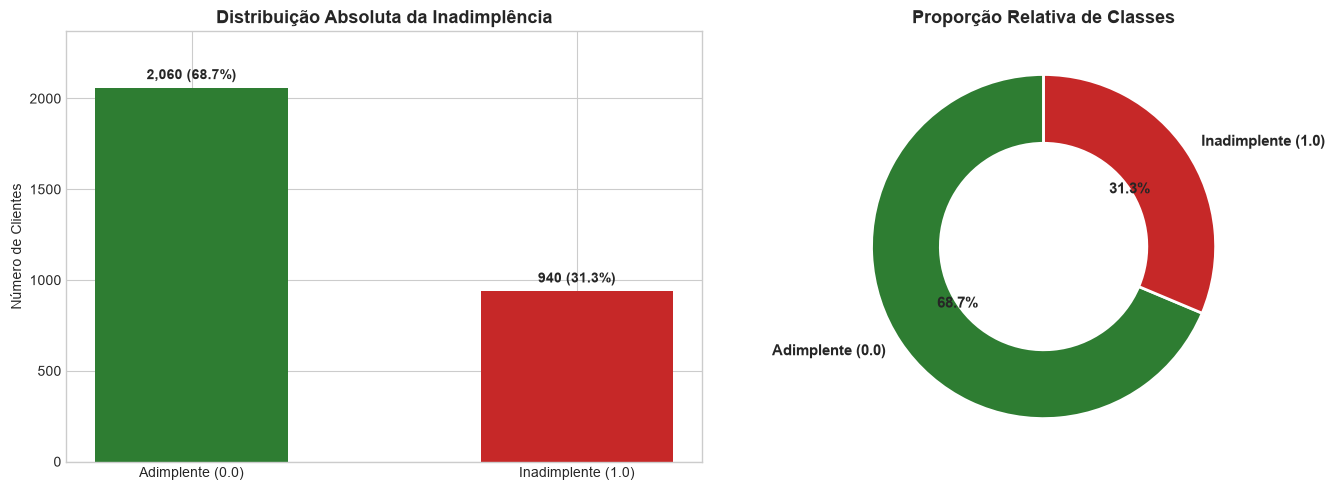

In [12]:
# Visualização gráfica da distribuição da variável alvo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cores institucionais: Verde para adimplente e Vermelho para inadimplente
cores_target = ['#2e7d32', '#c62828']

# Gráfico 1: Barras com valores absolutos e percentuais
bars = axes[0].bar(tabela_target.index, tabela_target['Quantidade'], color=cores_target, width=0.5)
axes[0].set_title('Distribuição Absoluta da Inadimplência', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Número de Clientes')
axes[0].set_ylim(0, max(tabela_target['Quantidade']) * 1.15)

for bar, pct in zip(bars, tabela_target['Proporção (%)']):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0, 
        bar.get_height() + 30, 
        f"{int(bar.get_height()):,} ({pct:.1f}%)", 
        ha='center', va='bottom', fontweight='bold'
    )

# Gráfico 2: Gráfico de Rosca (Donut Chart)
axes[1].pie(
    tabela_target['Quantidade'],
    labels=tabela_target.index,
    autopct='%1.1f%%',
    colors=cores_target,
    startangle=90,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    textprops=dict(fontweight='bold', fontsize=11)
)
axes[1].set_title('Proporção Relativa de Classes', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()


### 4. Análise Bivariada Preliminar: Idade do CNPJ vs. Inadimplência
Replicando o comportamento clássico de birô de crédito: estabelecimentos mais consolidados tendem a apresentar menor risco de inadimplência.


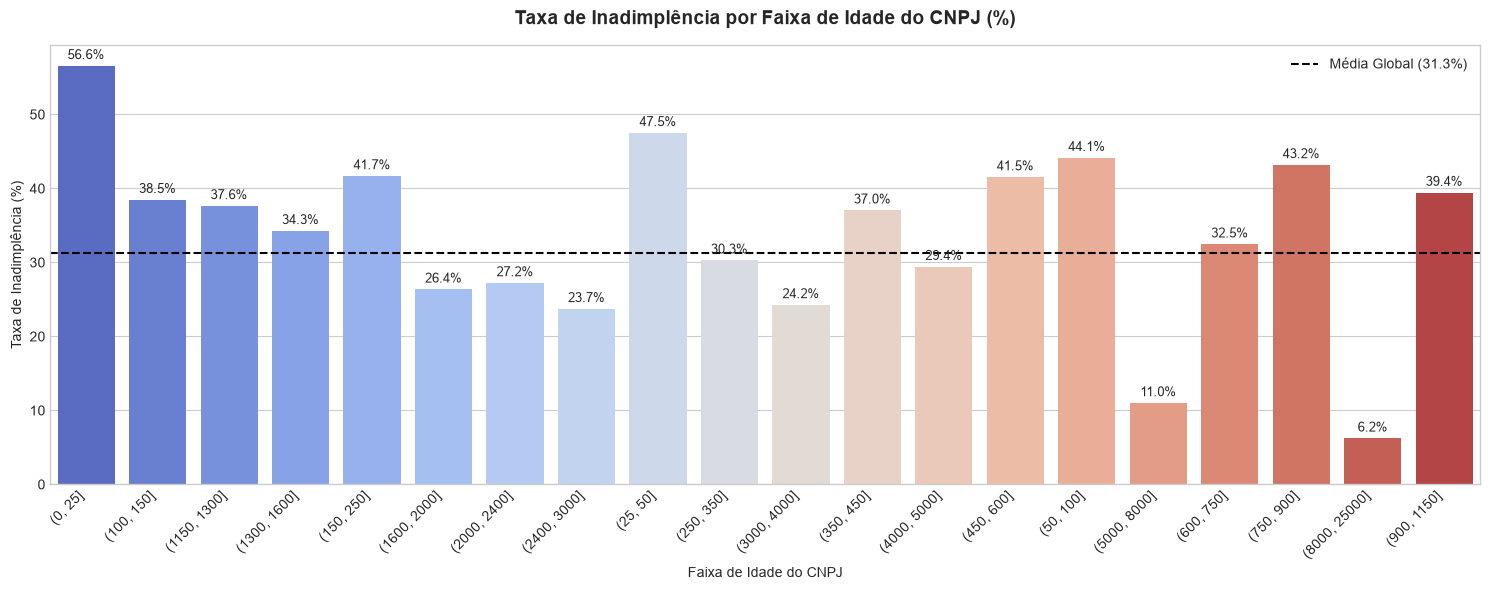

In [9]:
# Agrupamento da taxa de inadimplência por intervalo de idade do CNPJ
df_cnpj_analise = df_clientes.groupby('idade_cnpj')['inadimplente'].agg(
    total='count',
    inadimplentes='sum',
    taxa_inadimplencia='mean'
).reset_index()

df_cnpj_analise['taxa_pct'] = df_cnpj_analise['taxa_inadimplencia'] * 100
taxa_media_global = df_clientes['inadimplente'].mean() * 100

plt.figure(figsize=(15, 6))
ax = sns.barplot(data=df_cnpj_analise, x='idade_cnpj', y='taxa_pct', palette='coolwarm')
plt.title('Taxa de Inadimplência por Faixa de Idade do CNPJ (%)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Faixa de Idade do CNPJ')
plt.ylabel('Taxa de Inadimplência (%)')
plt.xticks(rotation=45, ha='right')
plt.axhline(taxa_media_global, color='black', linestyle='--', linewidth=1.5, 
            label=f'Média Global ({taxa_media_global:.1f}%)')

for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(f"{height:.1f}%",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3),
                    textcoords='offset points')

plt.legend()
plt.tight_layout()
plt.show()
